In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import matplotlib.lines as mlines
from Bio import SeqIO
from datetime import datetime
import warnings


In [13]:
FASTA_FILE_PATH = 'h3n2_clean.fasta' 

# ---------------------------------------------------------
# 1. PARSING THE FASTA FILE
# ---------------------------------------------------------
def load_fasta(fasta_path):
    print(f"Loading FASTA: {fasta_path}...")
    all_parsed_data = []
    
    total_count = 0
    date_fail_count = 0
    structure_fail_count = 0
    
    for record in SeqIO.parse(fasta_path, "fasta"):
        total_count += 1
        
        fields = record.id.split('|')
        if len(fields) < 6:
            structure_fail_count += 1
            continue
            
        unique_id = fields[0].strip()
        subtype   = fields[1].strip()
        clade     = fields[2].strip()
        date_str  = fields[3].strip()
        country   = fields[4].strip()
        zone      = fields[5].strip()
        
        try:
            date = datetime.strptime(date_str, '%Y-%m-%d')
            
            # Get the raw sequence and remove gaps/stops
            raw_seq = str(record.seq).replace('-', '').replace('*', '')
            
            # Check length and cut conditionally
            if len(raw_seq) >= 553:
                sequence = raw_seq[16:]
            else:
                sequence = raw_seq
                
            all_parsed_data.append(dict(
                date=date, sequence=sequence,
                id_full_header=record.id, unique_id=unique_id,
                clade=clade, subtype=subtype, country=country, zone=zone
            ))
        except ValueError:
            date_fail_count += 1
            continue
            
    df = pd.DataFrame(all_parsed_data)
    
    print(f"Total records: {len(df)}")
    print(f"✅ Total processed: {total_count}")
    print(f"📊 Successfully parsed: {len(df)}")
    print(f"⚠️  Skipped (Invalid date): {date_fail_count}")
    print(f"❌ Skipped (Wrong structure): {structure_fail_count}")
    print("-" * 40)
    
    return df

df = load_fasta(FASTA_FILE_PATH)

Loading FASTA: h3n2_clean.fasta...
Total records: 193102
✅ Total processed: 193102
📊 Successfully parsed: 193102
⚠️  Skipped (Invalid date): 0
❌ Skipped (Wrong structure): 0
----------------------------------------


In [14]:
# Cell 3
def assign_season(date_obj):
    if date_obj.month >= 2:
        return f"{date_obj.year}-{date_obj.year + 1}"
    else:
        return f"{date_obj.year - 1}-{date_obj.year}"

if not df.empty:
    print("Assigning seasons to data...")
    df['season'] = df['date'].apply(assign_season)
    
    # Filter for baseline season (2013-2014) onwards
    df['season_start_year'] = df['season'].apply(lambda x: int(x.split('-')[0]))
    df_filtered = df[df['season_start_year'] >= 2013].copy()
    
    print("Calculating positional amino acid frequencies per season...")
    seasons = sorted(df_filtered['season'].unique())
    season_freqs = {}
    
    for season in seasons:
        seqs = df_filtered[df_filtered['season'] == season]['sequence'].tolist()
        max_len = max((len(s) for s in seqs), default=0)
        
        pos_counts = {}
        for i in range(max_len):
            col = [s[i] for s in seqs if i < len(s)]
            if not col: 
                continue
            counts = Counter(col)
            total = len(col)
            pos_counts[i] = {aa: count / total for aa, count in counts.items()}
        season_freqs[season] = pos_counts
    
    print("Comparing seasons and identifying >40% changes...")
    changes = []
    
    for i in range(1, len(seasons)):
        prev_s = seasons[i-1]
        curr_s = seasons[i]
        
        prev_pos_data = season_freqs[prev_s]
        curr_pos_data = season_freqs[curr_s]
        
        common_positions = set(prev_pos_data.keys()).intersection(set(curr_pos_data.keys()))
        
        for pos in common_positions:
            prev_cons = max(prev_pos_data[pos], key=prev_pos_data[pos].get)
            curr_cons = max(curr_pos_data[pos], key=curr_pos_data[pos].get)
            
            major_variants = [aa for aa, freq in curr_pos_data[pos].items() if freq > 0.4]
            
            is_changed = False
            mut_type = ""
            plotted_aa = curr_cons 
            
            # Condition 1: Consensus Change
            if curr_cons != prev_cons:
                is_changed = True
                mut_type = "Consensus Change"
            else:
                # Condition 2: Variant Emergence
                for variant in major_variants:
                    if variant != prev_cons:
                        is_changed = True
                        mut_type = "Variant Emergence (>40%)"
                        plotted_aa = variant
                        break
            
            if is_changed:
                changes.append({
                    'Season': curr_s,
                    'Position': pos + 1,  # 1-based indexing
                    'Prev_Consensus': prev_cons,
                    'Curr_Consensus': curr_cons,
                    'Plotted_AA': plotted_aa,
                    'Mutation_Type': mut_type # Added field to distinguish in CSV
                })
    
    changes_df = pd.DataFrame(changes)
    changes_df.to_csv('season_aa_changes.csv', index=False)
    print(f"✅ Saved {len(changes_df)} position changes to 'season_aa_changes.csv'")
else:
    print("⚠️ Dataframe is empty. Please check your FASTA file.")

Assigning seasons to data...
Calculating positional amino acid frequencies per season...
Comparing seasons and identifying >40% changes...
✅ Saved 77 position changes to 'season_aa_changes.csv'


In [15]:
def assign_season(date_obj):
    # July (7) through December (12) start the new season
    if date_obj.month >= 7:
        return f"{date_obj.year}-{date_obj.year + 1}"
    # January (1) is the end of the previous year's season
    elif date_obj.month == 1:
        return f"{date_obj.year - 1}-{date_obj.year}"
    # February (2) through June (6) are excluded from this analysis
    else:
        return None

if not df.empty:
    print("Assigning seasons to data...")
    df['season'] = df['date'].apply(assign_season)
    
    # Filter out the Feb-June dates before doing string splits
    df_filtered = df[df['season'].notna()].copy()
    
    # Filter for baseline season (2013-2014) onwards
    df_filtered['season_start_year'] = df_filtered['season'].apply(lambda x: int(x.split('-')[0]))
    df_filtered = df_filtered[df_filtered['season_start_year'] >= 2013].copy()
    
    print("Calculating positional amino acid frequencies per season...")
    seasons = sorted(df_filtered['season'].unique())
    season_freqs = {}
    
    for season in seasons:
        seqs = df_filtered[df_filtered['season'] == season]['sequence'].tolist()
        max_len = max((len(s) for s in seqs), default=0)
        
        pos_counts = {}
        for i in range(max_len):
            col = [s[i] for s in seqs if i < len(s)]
            if not col: 
                continue
            counts = Counter(col)
            total = len(col)
            pos_counts[i] = {aa: count / total for aa, count in counts.items()}
        season_freqs[season] = pos_counts
    
    print("Comparing seasons and identifying >40% changes...")
    changes = []
    
    for i in range(1, len(seasons)):
        prev_s = seasons[i-1]
        curr_s = seasons[i]
        
        prev_pos_data = season_freqs[prev_s]
        curr_pos_data = season_freqs[curr_s]
        
        common_positions = set(prev_pos_data.keys()).intersection(set(curr_pos_data.keys()))
        
        for pos in common_positions:
            prev_cons = max(prev_pos_data[pos], key=prev_pos_data[pos].get)
            curr_cons = max(curr_pos_data[pos], key=curr_pos_data[pos].get)
            
            major_variants = [aa for aa, freq in curr_pos_data[pos].items() if freq > 0.4]
            
            is_changed = False
            mut_type = ""
            plotted_aa = curr_cons 
            
            # Condition 1: Consensus Change
            if curr_cons != prev_cons:
                is_changed = True
                mut_type = "Consensus Change"
            else:
                # Condition 2: Variant Emergence
                for variant in major_variants:
                    if variant != prev_cons:
                        is_changed = True
                        mut_type = "Variant Emergence (>40%)"
                        plotted_aa = variant
                        break
            
            if is_changed:
                changes.append({
                    'Season': curr_s,
                    'Position': pos + 1,  # 1-based indexing
                    'Prev_Consensus': prev_cons,
                    'Curr_Consensus': curr_cons,
                    'Plotted_AA': plotted_aa,
                    'Mutation_Type': mut_type # Added field to distinguish in CSV
                })
    
    changes_df = pd.DataFrame(changes)
    changes_df.to_csv('season_aa_changes.csv', index=False)
    print(f"✅ Saved {len(changes_df)} position changes to 'season_aa_changes.csv'")
else:
    print("⚠️ Dataframe is empty. Please check your FASTA file.")

Assigning seasons to data...
Calculating positional amino acid frequencies per season...
Comparing seasons and identifying >40% changes...
✅ Saved 83 position changes to 'season_aa_changes.csv'


✅ Successfully loaded 'season_aa_changes.csv'
Preparing data for Consensus Change plots...


/tmp/ipykernel_2494606/2133880440.py:55: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_epi['Sort_Key'] = df_epi.apply(lambda row: f"{row['Epitope_Site']}_{row['Position']:03d}", axis=1)


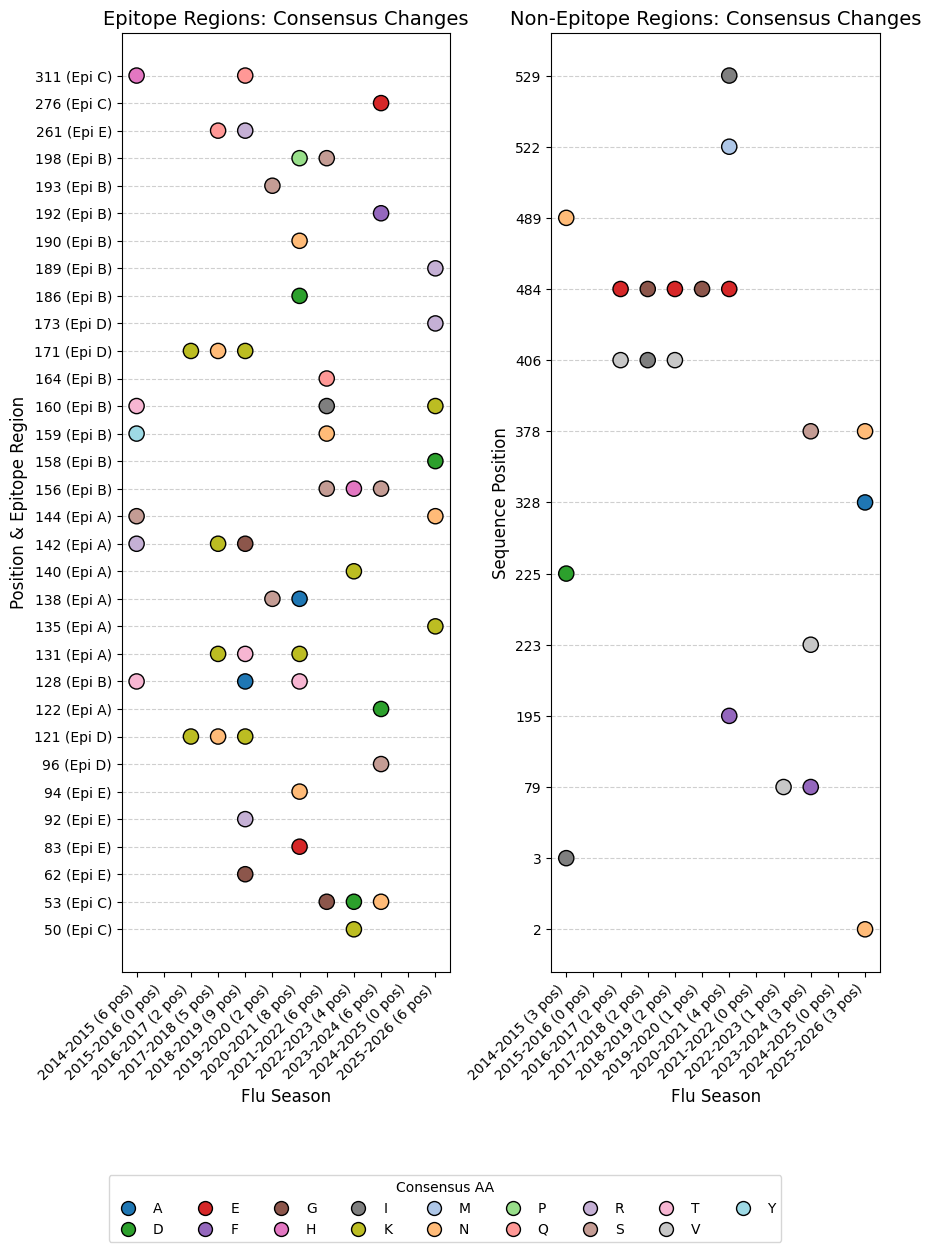

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

# 1. Load the previously saved CSV
try:
    changes_df = pd.read_csv('season_aa_changes.csv')
    print("✅ Successfully loaded 'season_aa_changes.csv'")
except FileNotFoundError:
    print("⚠️ CSV not found. Make sure 'season_aa_changes.csv' is in your directory.")
    changes_df = pd.DataFrame()

if not changes_df.empty:
    print("Preparing data for Consensus Change plots...")
    
    # 1. Define Epitopes
    epitope_sites = {
        'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
        'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
        'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
        'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
        'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
    }
    
    # Reverse map for easy lookup
    pos_to_epitope = {}
    for ep, positions in epitope_sites.items():
        for p in positions:
            pos_to_epitope[p] = ep

    # 2. Filter for ONLY Consensus Changes
    df_plot = changes_df[changes_df['Mutation_Type'] == 'Consensus Change'].copy()
    
    if df_plot.empty:
        print("⚠️ No direct consensus changes found to plot.")
    else:
        # Tag positions
        df_plot['Epitope_Site'] = df_plot['Position'].apply(lambda x: pos_to_epitope.get(x, 'Non-Epitope'))
        
        # --- NEW: Master Season List & Sorting ---
        # Get all seasons present in the df, add the missing ones, and sort them chronologically
        all_seasons = set(changes_df['Season'].dropna().unique())
        missing_seasons = ['2015-2016', '2024-2025'] # Adjust to '2015-16' if your data format differs
        all_seasons.update(missing_seasons)
        sorted_seasons = sorted(list(all_seasons))
        
        # Create an X-axis numerical mapping (forces correct order and spacing for empty seasons)
        x_map_seasons = {s: i for i, s in enumerate(sorted_seasons)}
        
        # Split DataFrames
        df_epi = df_plot[df_plot['Epitope_Site'] != 'Non-Epitope']
        df_non = df_plot[df_plot['Epitope_Site'] == 'Non-Epitope']
        
        # Determine exact ordered category Y-mappings
        df_epi['Sort_Key'] = df_epi.apply(lambda row: f"{row['Epitope_Site']}_{row['Position']:03d}", axis=1)
        df_epi = df_epi.sort_values('Sort_Key')
        unique_epi_pos = sorted(df_epi['Position'].unique())
        y_map_epi = {pos: i for i, pos in enumerate(unique_epi_pos)}
        y_labels_epi = [f"{p} (Epi {pos_to_epitope[p]})" for p in unique_epi_pos]
        
        unique_non_pos = sorted(df_non['Position'].unique())
        y_map_non = {pos: i for i, pos in enumerate(unique_non_pos)}
        y_labels_non = [str(p) for p in unique_non_pos]
        
        # --- NEW: Count mutations per season for X-axis labels ---
        epi_counts = df_epi['Season'].value_counts().to_dict()
        non_counts = df_non['Season'].value_counts().to_dict()
        
        x_labels_epi = [f"{s} ({epi_counts.get(s, 0)} pos)" for s in sorted_seasons]
        x_labels_non = [f"{s} ({non_counts.get(s, 0)} pos)" for s in sorted_seasons]
        
        # Amino Acid Colors
        aa_colors = {
            'A': '#1f77b4', 'C': '#ff7f0e', 'D': '#2ca02c', 'E': '#d62728',
            'F': '#9467bd', 'G': '#8c564b', 'H': '#e377c2', 'I': '#7f7f7f',
            'K': '#bcbd22', 'L': '#17becf', 'M': '#aec7e8', 'N': '#ffbb78',
            'P': '#98df8a', 'Q': '#ff9896', 'R': '#c5b0d5', 'S': '#c49c94',
            'T': '#f7b6d2', 'V': '#c7c7c7', 'W': '#dbdb8d', 'Y': '#9edae5'
        }
        
        # 3. Create the dual-plot figure
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, max(6, len(unique_epi_pos)*0.4)))
        
        # Graph A: Epitope Positions
        if not df_epi.empty:
            c_epi = df_epi['Plotted_AA'].map(aa_colors).fillna('#808080')
            y_coords_epi = df_epi['Position'].map(y_map_epi)
            x_coords_epi = df_epi['Season'].map(x_map_seasons) # Map to numerical X
            
            ax1.scatter(x_coords_epi, y_coords_epi, c=c_epi, s=120, edgecolors='black', zorder=3)
            ax1.set_yticks(range(len(unique_epi_pos)))
            ax1.set_yticklabels(y_labels_epi)
            
            # Apply custom X-axis ticks & labels
            ax1.set_xticks(range(len(sorted_seasons)))
            ax1.set_xticklabels(x_labels_epi, rotation=45, ha='right')
            
            ax1.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
            ax1.set_title('Epitope Regions: Consensus Changes', fontsize=14)
            ax1.set_xlabel('Flu Season', fontsize=12)
            ax1.set_ylabel('Position & Epitope Region', fontsize=12)
            
        # Graph B: Non-Epitope Positions
        if not df_non.empty:
            c_non = df_non['Plotted_AA'].map(aa_colors).fillna('#808080')
            y_coords_non = df_non['Position'].map(y_map_non)
            x_coords_non = df_non['Season'].map(x_map_seasons) # Map to numerical X
            
            ax2.scatter(x_coords_non, y_coords_non, c=c_non, s=120, edgecolors='black', zorder=3)
            ax2.set_yticks(range(len(unique_non_pos)))
            ax2.set_yticklabels(y_labels_non)
            
            # Apply custom X-axis ticks & labels
            ax2.set_xticks(range(len(sorted_seasons)))
            ax2.set_xticklabels(x_labels_non, rotation=45, ha='right')
            
            ax2.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
            ax2.set_title('Non-Epitope Regions: Consensus Changes', fontsize=14)
            ax2.set_xlabel('Flu Season', fontsize=12)
            ax2.set_ylabel('Sequence Position', fontsize=12)
        
        # Unified Legend
        unique_aas = sorted(df_plot['Plotted_AA'].unique())
        legend_elements = [
            mlines.Line2D([0], [0], marker='o', color='w', 
                          markerfacecolor=aa_colors.get(aa, '#808080'), 
                          markeredgecolor='black', markersize=10, label=aa)
            for aa in unique_aas
        ]
        
        # Place legend nicely outside the plots
        num_cols = (len(legend_elements) + 1) // 2
        fig.legend(handles=legend_elements, title='Consensus AA', 
                   bbox_to_anchor=(0.5, 0.02), loc='lower center',
                   ncol=num_cols)
        
        # Adjust layout to account for rotated X labels and bottom legend
        plt.tight_layout(rect=[0, 0.12, 1, 1])
        plt.savefig("Consensus_Change.png", dpi=300, bbox_inches='tight')
        plt.show() 
else:
    print("⚠️ No mutations were found between seasons.")

Preparing data for Consensus Change plots...


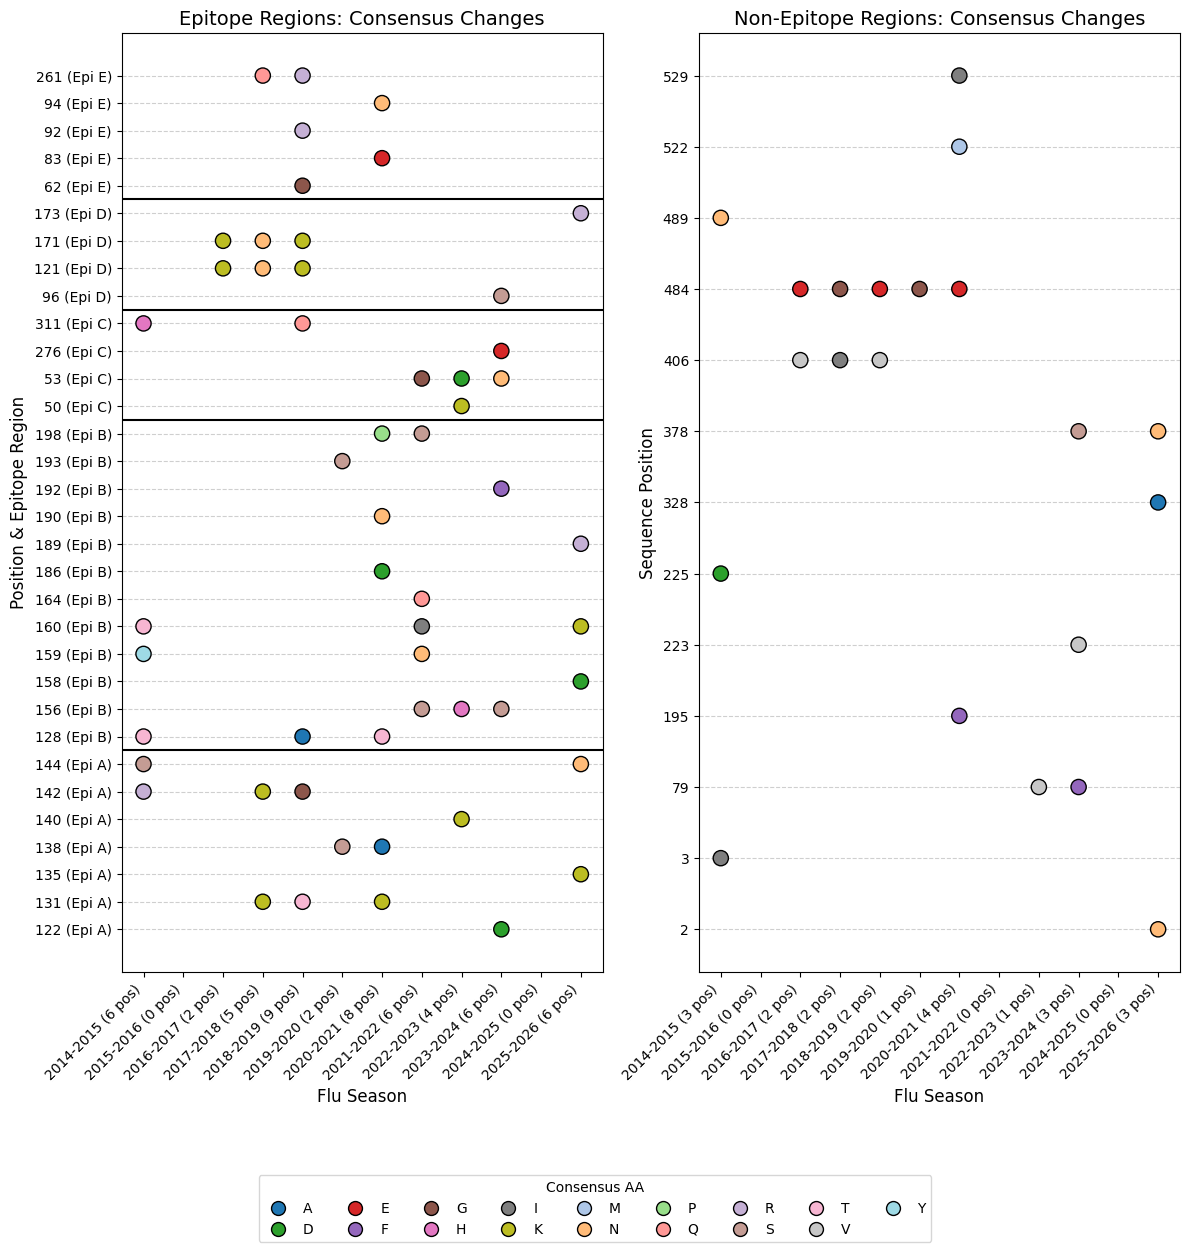

In [23]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

if not changes_df.empty:
    print("Preparing data for Consensus Change plots...")
    
    # 1. Define Epitopes
    epitope_sites = {
        'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
        'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
        'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
        'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
        'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
    }
    
    # Reverse map for easy lookup
    pos_to_epitope = {}
    for ep, positions in epitope_sites.items():
        for p in positions:
            pos_to_epitope[p] = ep

    # 2. Filter for ONLY Consensus Changes
    df_plot = changes_df[changes_df['Mutation_Type'] == 'Consensus Change'].copy()
    
    if df_plot.empty:
        print("⚠️ No direct consensus changes found to plot.")
    else:
        # Tag positions
        df_plot['Epitope_Site'] = df_plot['Position'].apply(lambda x: pos_to_epitope.get(x, 'Non-Epitope'))
        
        # --- NEW X-AXIS LOGIC: Master Season List & Sorting ---
        all_seasons = set(changes_df['Season'].dropna().unique())
        missing_seasons = ['2015-2016', '2024-2025'] # Ensures these empty seasons are included
        all_seasons.update(missing_seasons)
        sorted_seasons = sorted(list(all_seasons))
        
        # Create an X-axis numerical mapping (forces correct order and spacing for empty seasons)
        x_map_seasons = {s: i for i, s in enumerate(sorted_seasons)}
        
        # Split DataFrames
        df_epi = df_plot[df_plot['Epitope_Site'] != 'Non-Epitope'].copy()
        df_non = df_plot[df_plot['Epitope_Site'] == 'Non-Epitope'].copy()
        
        # Determine exact ordered category Y-mappings (Grouped by Epitope)
        df_epi['Sort_Key'] = df_epi.apply(lambda row: f"{row['Epitope_Site']}_{row['Position']:03d}", axis=1)
        df_epi = df_epi.sort_values('Sort_Key')
        
        # FIXED: Extract unique positions in the sorted order
        unique_epi_pos = df_epi['Position'].drop_duplicates().tolist()
        y_map_epi = {pos: i for i, pos in enumerate(unique_epi_pos)}
        y_labels_epi = [f"{p} (Epi {pos_to_epitope[p]})" for p in unique_epi_pos]
        
        unique_non_pos = sorted(df_non['Position'].unique())
        y_map_non = {pos: i for i, pos in enumerate(unique_non_pos)}
        y_labels_non = [str(p) for p in unique_non_pos]
        
        # --- NEW X-AXIS LOGIC: Count mutations per season for labels ---
        epi_counts = df_epi['Season'].value_counts().to_dict()
        non_counts = df_non['Season'].value_counts().to_dict()
        
        x_labels_epi = [f"{s} ({epi_counts.get(s, 0)} pos)" for s in sorted_seasons]
        x_labels_non = [f"{s} ({non_counts.get(s, 0)} pos)" for s in sorted_seasons]
        
        # Amino Acid Colors
        aa_colors = {
            'A': '#1f77b4', 'C': '#ff7f0e', 'D': '#2ca02c', 'E': '#d62728',
            'F': '#9467bd', 'G': '#8c564b', 'H': '#e377c2', 'I': '#7f7f7f',
            'K': '#bcbd22', 'L': '#17becf', 'M': '#aec7e8', 'N': '#ffbb78',
            'P': '#98df8a', 'Q': '#ff9896', 'R': '#c5b0d5', 'S': '#c49c94',
            'T': '#f7b6d2', 'V': '#c7c7c7', 'W': '#dbdb8d', 'Y': '#9edae5'
        }
        
        # 3. Create the dual-plot figure
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, max(6, len(unique_epi_pos)*0.4)))
        
        # Graph A: Epitope Positions
        if not df_epi.empty:
            c_epi = df_epi['Plotted_AA'].map(aa_colors).fillna('#808080')
            y_coords_epi = df_epi['Position'].map(y_map_epi)
            x_coords_epi = df_epi['Season'].map(x_map_seasons) # Map to numerical X
            
            ax1.scatter(x_coords_epi, y_coords_epi, c=c_epi, s=120, edgecolors='black', zorder=3)
            ax1.set_yticks(range(len(unique_epi_pos)))
            ax1.set_yticklabels(y_labels_epi)
            
            # Apply custom X-axis ticks & labels
            ax1.set_xticks(range(len(sorted_seasons)))
            ax1.set_xticklabels(x_labels_epi, rotation=45, ha='right')
            
            ax1.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
            
            # Draw horizontal lines between different epitopes
            if len(unique_epi_pos) > 0:
                current_ep = pos_to_epitope[unique_epi_pos[0]]
                for i, pos in enumerate(unique_epi_pos):
                    ep = pos_to_epitope[pos]
                    if ep != current_ep:
                        # Draw line halfway between the previous and current y-position
                        ax1.axhline(y=i - 0.5, color='black', linewidth=1.5, zorder=2)
                        current_ep = ep
            
            ax1.set_title('Epitope Regions: Consensus Changes', fontsize=14)
            ax1.set_xlabel('Flu Season', fontsize=12)
            ax1.set_ylabel('Position & Epitope Region', fontsize=12)
            
        # Graph B: Non-Epitope Positions
        if not df_non.empty:
            c_non = df_non['Plotted_AA'].map(aa_colors).fillna('#808080')
            y_coords_non = df_non['Position'].map(y_map_non)
            x_coords_non = df_non['Season'].map(x_map_seasons) # Map to numerical X
            
            ax2.scatter(x_coords_non, y_coords_non, c=c_non, s=120, edgecolors='black', zorder=3)
            ax2.set_yticks(range(len(unique_non_pos)))
            ax2.set_yticklabels(y_labels_non)
            
            # Apply custom X-axis ticks & labels
            ax2.set_xticks(range(len(sorted_seasons)))
            ax2.set_xticklabels(x_labels_non, rotation=45, ha='right')
            
            ax2.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
            ax2.set_title('Non-Epitope Regions: Consensus Changes', fontsize=14)
            ax2.set_xlabel('Flu Season', fontsize=12)
            ax2.set_ylabel('Sequence Position', fontsize=12)
        
        # Unified Legend
        unique_aas = sorted(df_plot['Plotted_AA'].unique())
        legend_elements = [
            mlines.Line2D([0], [0], marker='o', color='w', 
                          markerfacecolor=aa_colors.get(aa, '#808080'), 
                          markeredgecolor='black', markersize=10, label=aa)
            for aa in unique_aas
        ]
        
        # Place legend nicely outside the plots
        num_cols = (len(legend_elements) + 1) // 2
        fig.legend(handles=legend_elements, title='Consensus AA', 
                   bbox_to_anchor=(0.5, 0.02), loc='lower center',
                   ncol=num_cols)
        
        plt.tight_layout(rect=[0, 0.12, 1, 1])
        plt.savefig("Consensus_Change.png", dpi=300, bbox_inches='tight')
        plt.show() 
else:
    print("⚠️ No mutations were found between seasons.")

Preparing data for Consensus Change plots...


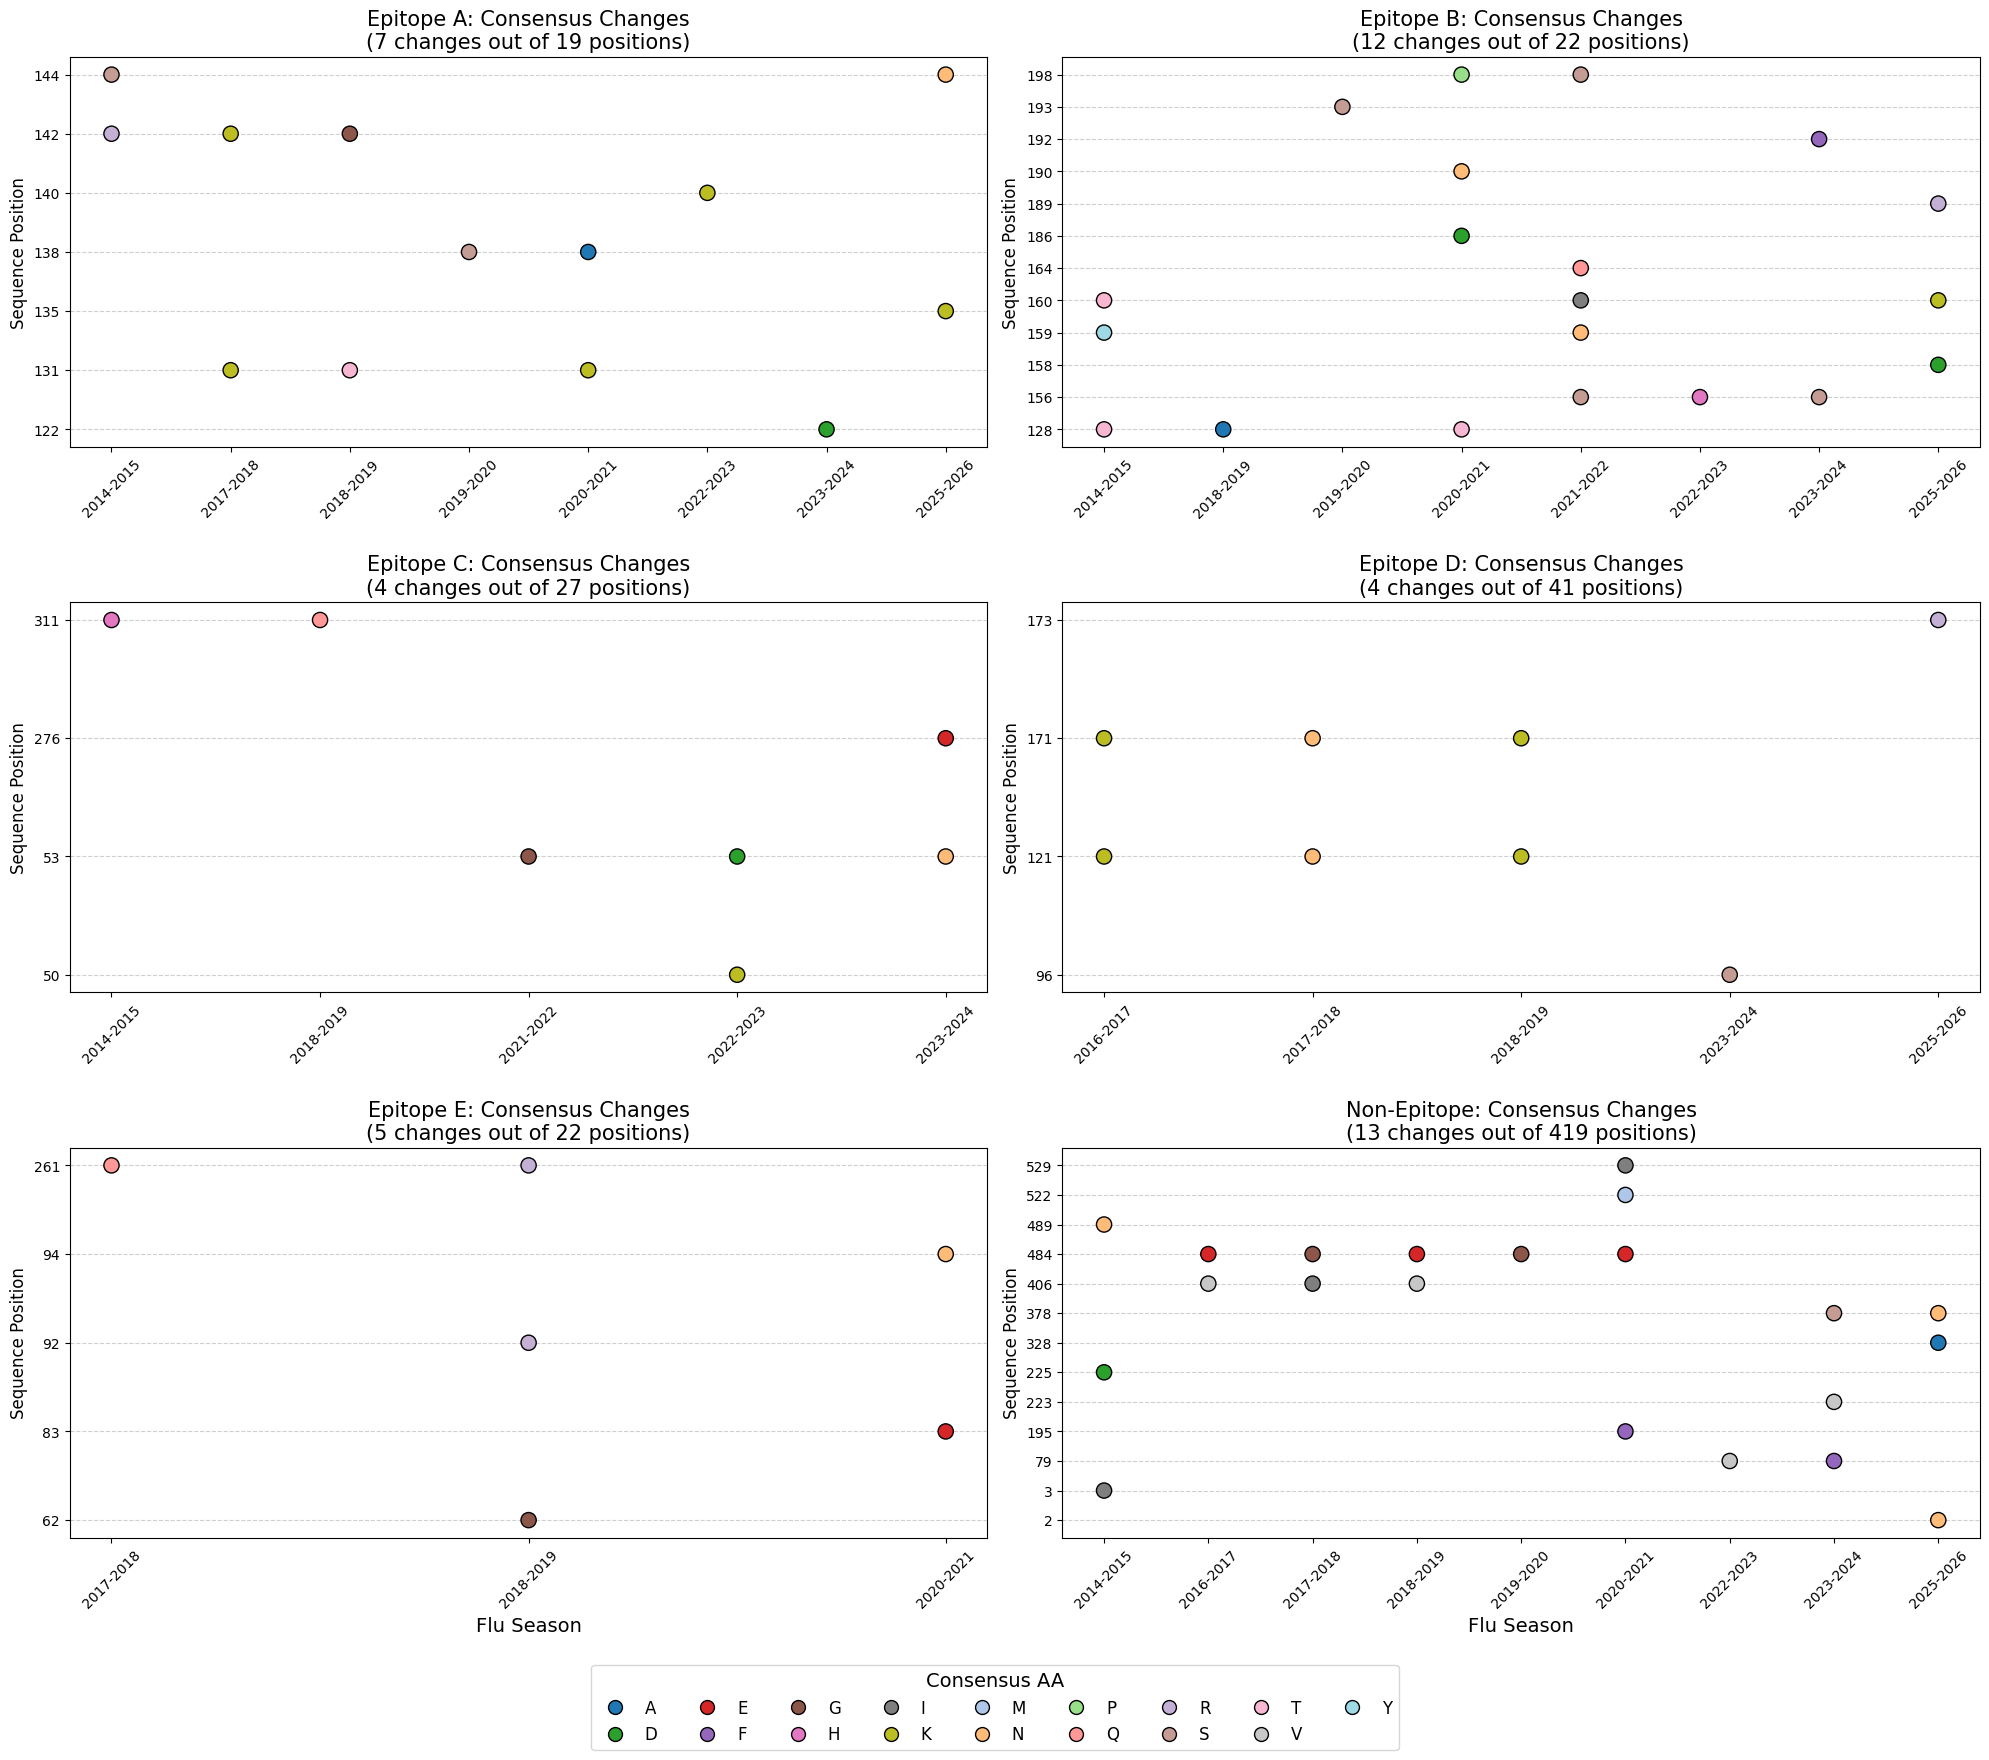

In [8]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

if not changes_df.empty:
    print("Preparing data for Consensus Change plots...")
    
    # 1. Define Epitopes
    epitope_sites = {
        'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
        'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
        'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
        'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
        'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
    }
    
    # Calculate total positions per region
    total_positions = {ep: len(positions) for ep, positions in epitope_sites.items()}
    total_positions['Non-Epitope'] = 550 - sum(total_positions.values())
    
    # Reverse map for easy lookup
    pos_to_epitope = {}
    for ep, positions in epitope_sites.items():
        for p in positions:
            pos_to_epitope[p] = ep

    # 2. Filter for ONLY Consensus Changes
    df_plot = changes_df[changes_df['Mutation_Type'] == 'Consensus Change'].copy()
    
    if df_plot.empty:
        print("⚠️ No direct consensus changes found to plot.")
    else:
        # Tag positions
        df_plot['Epitope_Site'] = df_plot['Position'].apply(lambda x: pos_to_epitope.get(x, 'Non-Epitope'))
        
        # Amino Acid Colors
        aa_colors = {
            'A': '#1f77b4', 'C': '#ff7f0e', 'D': '#2ca02c', 'E': '#d62728',
            'F': '#9467bd', 'G': '#8c564b', 'H': '#e377c2', 'I': '#7f7f7f',
            'K': '#bcbd22', 'L': '#17becf', 'M': '#aec7e8', 'N': '#ffbb78',
            'P': '#98df8a', 'Q': '#ff9896', 'R': '#c5b0d5', 'S': '#c49c94',
            'T': '#f7b6d2', 'V': '#c7c7c7', 'W': '#dbdb8d', 'Y': '#9edae5'
        }
        
        # 3. Create the 3x2 grid layout
        fig, axes = plt.subplots(3, 2, figsize=(20, 18))
        axes = axes.flatten() 
        
        # Define the order of panels
        regions_to_plot = ['A', 'B', 'C', 'D', 'E', 'Non-Epitope']
        
        for i, region in enumerate(regions_to_plot):
            ax = axes[i]
            df_subset = df_plot[df_plot['Epitope_Site'] == region].copy()
            
            # Calculate observed changes for the title
            observed_changes = len(df_subset['Position'].unique()) if not df_subset.empty else 0
            total_pos = total_positions[region]
            
            # Set Title dynamically
            if region != 'Non-Epitope':
                title = f'Epitope {region}: Consensus Changes\n({observed_changes} changes out of {total_pos} positions)'
            else:
                title = f'Non-Epitope: Consensus Changes\n({observed_changes} changes out of {total_pos} positions)'
                
            ax.set_title(title, fontsize=15)
            ax.set_ylabel('Sequence Position', fontsize=12)
            
            if not df_subset.empty:
                # Determine exact ordered category Y-mappings for this specific subset
                unique_pos = sorted(df_subset['Position'].unique())
                y_map = {pos: idx for idx, pos in enumerate(unique_pos)}
                y_labels = [str(p) for p in unique_pos]
                
                c_colors = df_subset['Plotted_AA'].map(aa_colors).fillna('#808080')
                y_coords = df_subset['Position'].map(y_map)
                
                # Plot the scatter points
                ax.scatter(df_subset['Season'], y_coords, c=c_colors, s=120, edgecolors='black', zorder=3)
                
                # Format Y-axis
                ax.set_yticks(range(len(unique_pos)))
                ax.set_yticklabels(y_labels)
            else:
                # Handle cases where an epitope has no mutations
                ax.text(0.5, 0.5, 'No consensus changes observed', 
                        horizontalalignment='center', verticalalignment='center', 
                        transform=ax.transAxes, fontsize=12, color='gray')
                ax.set_yticks([])
                
            # Formatting the grid and axes
            ax.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
            ax.tick_params(axis='x', rotation=45)
            
            # Only add the 'Flu Season' label to the bottom plots to reduce clutter
            if i >= 4:
                ax.set_xlabel('Flu Season', fontsize=14)

        # Unified Legend
        unique_aas = sorted(df_plot['Plotted_AA'].unique())
        legend_elements = [
            mlines.Line2D([0], [0], marker='o', color='w', 
                          markerfacecolor=aa_colors.get(aa, '#808080'), 
                          markeredgecolor='black', markersize=10, label=aa)
            for aa in unique_aas
        ]
        
        # Place legend nicely outside the subplots at the very bottom
        num_cols = min((len(legend_elements) + 1) // 2, 10) # Max 10 columns
        fig.legend(handles=legend_elements, title='Consensus AA', 
                   bbox_to_anchor=(0.5, 0.02), loc='lower center',
                   ncol=num_cols, fontsize=12, title_fontsize=14)
        
        # Adjust layout to make room for the legend at the bottom
        plt.tight_layout(rect=[0, 0.08, 1, 1], h_pad=2.5)
        plt.savefig("Consensus_Change_Panels.png", dpi=300, bbox_inches='tight')
        plt.show() 
else:
    print("⚠️ No mutations were found between seasons.")

In [13]:
if not df.empty:
    print("Assigning custom Base and Target windows...")
    df['date'] = pd.to_datetime(df['date'])
    
    # Get the range of years in your dataset
    min_year = df['date'].dt.year.min()
    max_year = df['date'].dt.year.max()
    
    changes = []
    
    # We start from 2014, as 2014 is your first "Target Year" example
    # Example: Y = 2014
    # Base: Feb 2013 - Jan 2014
    # Target: Jul 2014 - Jan 2015
    for Y in range(2014, max_year + 1):
        
        # 1. Define the exact date boundaries
        base_start = pd.Timestamp(year=Y-1, month=2, day=1)
        base_end = pd.Timestamp(year=Y, month=1, day=31)
        
        target_start = pd.Timestamp(year=Y, month=7, day=1)
        target_end = pd.Timestamp(year=Y+1, month=1, day=31)
        
        # 2. Filter sequences for these specific windows
        base_seqs = df[(df['date'] >= base_start) & (df['date'] <= base_end)]['sequence'].tolist()
        target_seqs = df[(df['date'] >= target_start) & (df['date'] <= target_end)]['sequence'].tolist()
        
        # Skip this year if we are missing data for either window
        if not base_seqs or not target_seqs:
            continue
            
        # Helper function to calculate frequencies for a list of sequences
        def get_frequencies(seqs):
            max_len = max((len(s) for s in seqs), default=0)
            pos_counts = {}
            for i in range(max_len):
                col = [s[i] for s in seqs if i < len(s)]
                if not col: 
                    continue
                counts = Counter(col)
                total = len(col)
                pos_counts[i] = {aa: count / total for aa, count in counts.items()}
            return pos_counts

        # 3. Calculate frequencies for Base and Target
        base_pos_data = get_frequencies(base_seqs)
        target_pos_data = get_frequencies(target_seqs)
        
        # 4. Compare and identify >40% changes (Original Logic)
        common_positions = set(base_pos_data.keys()).intersection(set(target_pos_data.keys()))
        
        for pos in common_positions:
            prev_cons = max(base_pos_data[pos], key=base_pos_data[pos].get)
            curr_cons = max(target_pos_data[pos], key=target_pos_data[pos].get)
            
            major_variants = [aa for aa, freq in target_pos_data[pos].items() if freq > 0.4]
            
            is_changed = False
            mut_type = ""
            plotted_aa = curr_cons 
            
            # Condition 1: Consensus Change
            if curr_cons != prev_cons:
                is_changed = True
                mut_type = "Consensus Change"
            else:
                # Condition 2: Variant Emergence
                for variant in major_variants:
                    if variant != prev_cons:
                        is_changed = True
                        mut_type = "Variant Emergence (>40%)"
                        plotted_aa = variant
                        break
            
            if is_changed:
                changes.append({
                    'Target_Season': f"{Y}-{Y+1}",
                    'Ref_Window': f"Feb{Y-1}-Jan{Y}",
                    'Target_Window': f"Jul{Y}-Jan{Y+1}",
                    'Position': pos + 1,  # 1-based indexing
                    'Prev_Consensus': prev_cons,
                    'Curr_Consensus': curr_cons,
                    'Plotted_AA': plotted_aa,
                    'Mutation_Type': mut_type
                })
                
    changes_df = pd.DataFrame(changes)
    changes_df.to_csv('season_aa_changes_custom_windows.csv', index=False)
    print(f"✅ Saved {len(changes_df)} position changes to 'season_aa_changes_custom_windows.csv'")

else:
    print("⚠️ Dataframe is empty. Please check your FASTA file.")

Assigning custom Base and Target windows...
✅ Saved 94 position changes to 'season_aa_changes_custom_windows.csv'


In [17]:
def analyze_2015_2016_season_carefully(df):
    print("🔍 Running Deep-Dive Analysis for 2015-2016 Season...\n")
    
    # 1. Ensure datetime format
    df['date'] = pd.to_datetime(df['date'])
    
    # 2. Hardcode the exact windows used by the backtest code
    # Reference: The final stable year before the target season
    ref_start = pd.Timestamp('2014-02-01')
    ref_end   = pd.Timestamp('2015-01-31')
    
    # Target: The late-season test window (August to January)
    target_start = pd.Timestamp('2015-08-01')
    target_end   = pd.Timestamp('2016-01-31')
    
    # 3. Filter sequences
    ref_seqs = df[(df['date'] >= ref_start) & (df['date'] <= ref_end)]['sequence'].tolist()
    target_seqs = df[(df['date'] >= target_start) & (df['date'] <= target_end)]['sequence'].tolist()
    
    print(f"📊 Data Pool:")
    print(f"   Reference Sequences (Feb 2014 - Jan 2015): {len(ref_seqs)}")
    print(f"   Target Sequences    (Aug 2015 - Jan 2016): {len(target_seqs)}\n")
    
    if not ref_seqs or not target_seqs:
        print("⚠️ Not enough data in these specific windows to run the analysis.")
        return
        
    # Helper function to get the top 3 amino acids and their percentages
    def get_top_aas(seqs, pos):
        aas = [s[pos] for s in seqs if pos < len(s) and s[pos] not in ['-', 'X', '<PAD>']]
        if not aas:
            return None, "No Data"
        
        counts = Counter(aas)
        total = len(aas)
        top_consensus = counts.most_common(1)[0][0]
        
        # Create a readable string of the top variants
        details = ", ".join([f"{aa}({(count/total)*100:.1f}%)" for aa, count in counts.most_common(3)])
        return top_consensus, details

    # 4. Find the maximum sequence length to iterate through
    max_len = max(max((len(s) for s in ref_seqs), default=0), 
                  max((len(s) for s in target_seqs), default=0))
    
    shifted_positions = []
    
    print("-" * 75)
    print(f"{'Pos':<6} | {'Ref Consensus (14-15)':<25} | {'Target Consensus (15-16)':<25}")
    print("-" * 75)
    
    # 5. Scan every position for absolute consensus shifts
    for pos in range(max_len):
        ref_top, ref_details = get_top_aas(ref_seqs, pos)
        target_top, target_details = get_top_aas(target_seqs, pos)
        
        # Ensure we have valid data for both windows at this position
        if ref_top and target_top:
            
            # THE STRICT SHIFT TRIGGER: Did the #1 most common AA completely flip?
            if ref_top != target_top:
                shifted_positions.append(pos + 1)
                print(f"{pos + 1:<6} | {ref_details:<25} | {target_details:<25}")
    target_positions = [3, 142, 144, 160, 311] # Replace with your actual 5 positions
    for pos in target_positions:
        idx = pos - 1
        ref_aa, ref_details = get_top_aas(ref_seqs, idx)
        target_aa, target_details = get_top_aas(target_seqs, idx)
        print(f"Pos {pos}: Ref={ref_aa} | Target={target_aa} | Target Breakdown: {target_details}")
                
    print("-" * 75)
    print(f"\n✅ Deep-Dive Complete. Found {len(shifted_positions)} shifted positions.")
    print(f"Positions: {shifted_positions}")

# To run this:
analyze_2015_2016_season_carefully(df)

🔍 Running Deep-Dive Analysis for 2015-2016 Season...

📊 Data Pool:
   Reference Sequences (Feb 2014 - Jan 2015): 6616
   Target Sequences    (Aug 2015 - Jan 2016): 2735

---------------------------------------------------------------------------
Pos    | Ref Consensus (14-15)     | Target Consensus (15-16) 
---------------------------------------------------------------------------
Pos 3: Ref=I | Target=I | Target Breakdown: I(88.0%), L(11.0%), T(0.4%)
Pos 142: Ref=R | Target=R | Target Breakdown: R(66.3%), K(20.8%), G(12.8%)
Pos 144: Ref=S | Target=S | Target Breakdown: S(84.6%), N(11.0%), R(3.3%)
Pos 160: Ref=T | Target=T | Target Breakdown: T(83.4%), K(15.8%), A(0.3%)
Pos 311: Ref=H | Target=H | Target Breakdown: H(88.6%), Q(11.3%), L(0.0%)
---------------------------------------------------------------------------

✅ Deep-Dive Complete. Found 0 shifted positions.
Positions: []


Preparing data for Consensus Change plots...


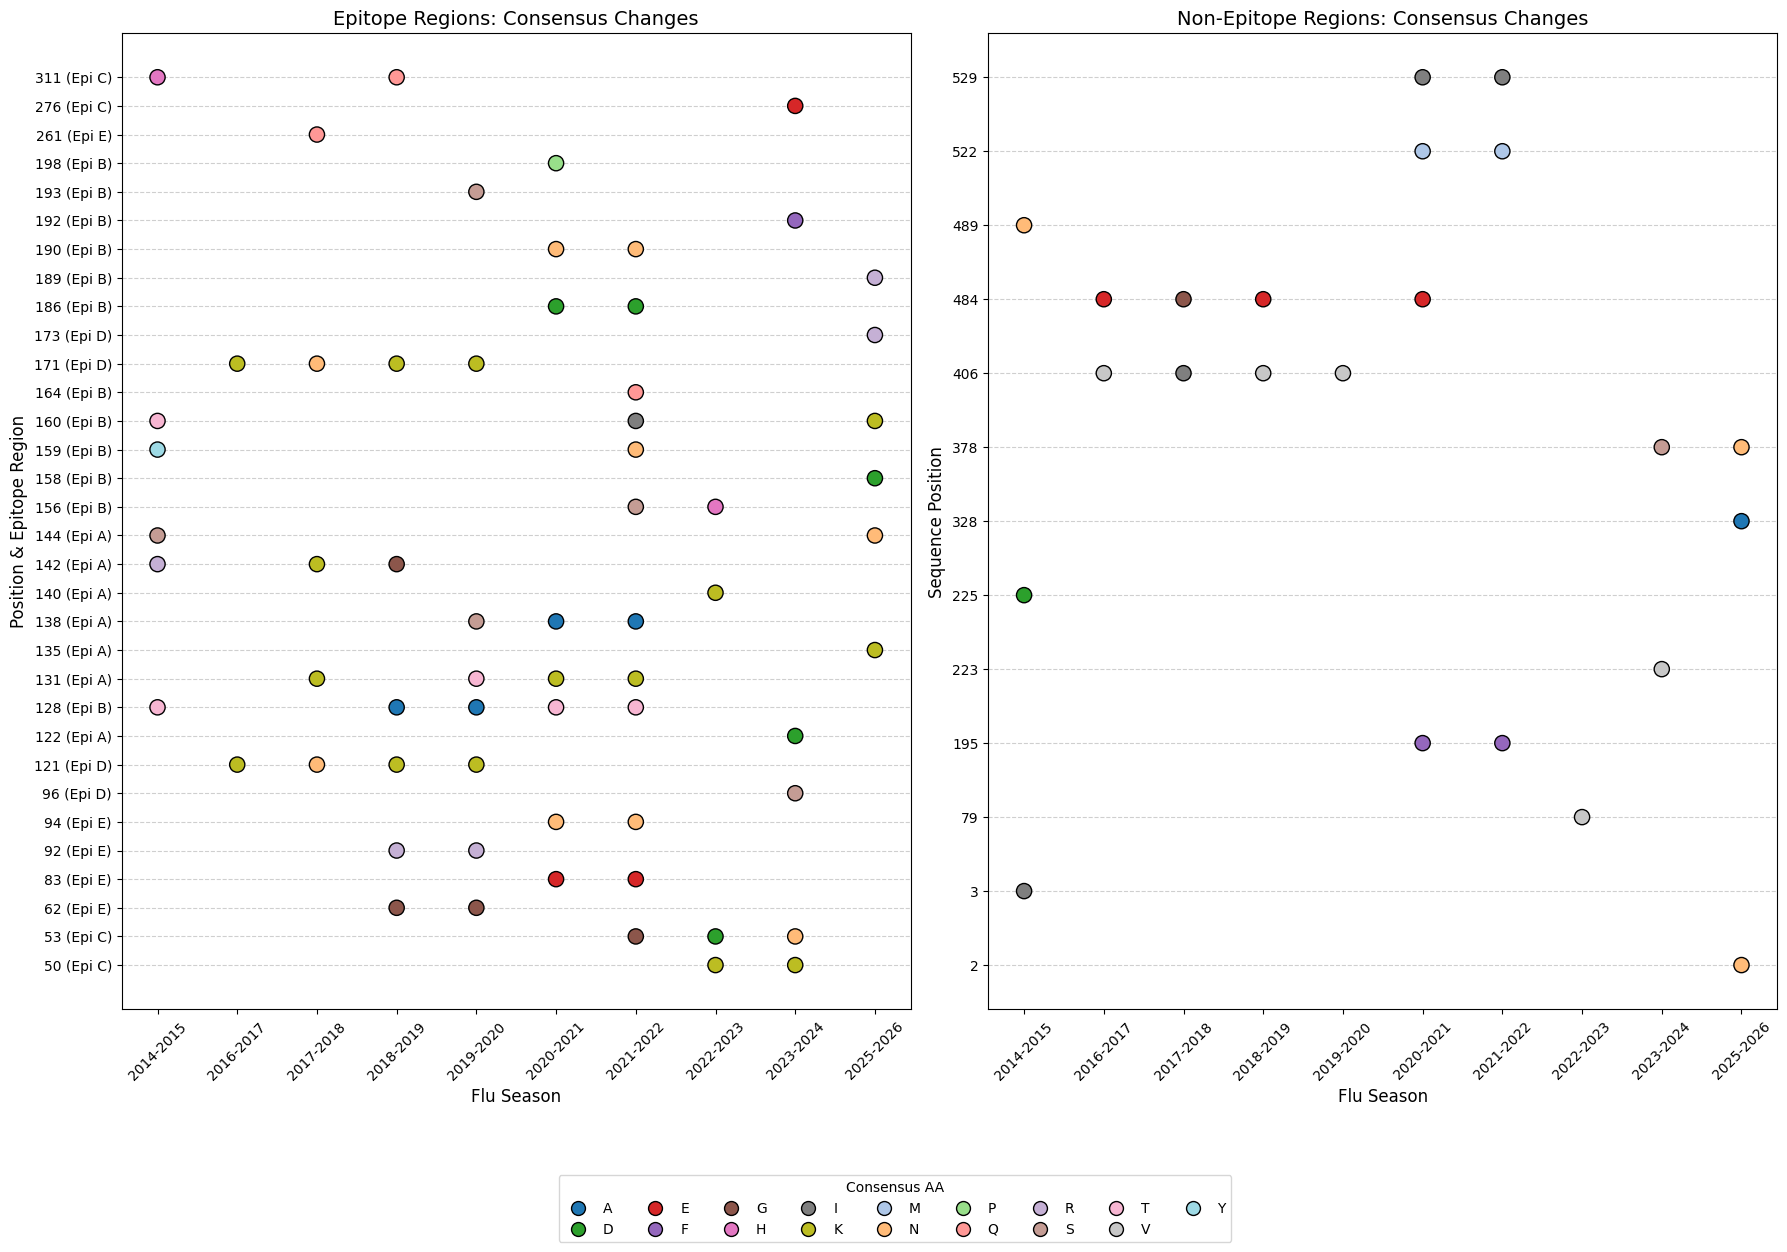

In [16]:
# Cell 4
if not changes_df.empty:
    print("Preparing data for Consensus Change plots...")
    
    # 1. Define Epitopes
    epitope_sites = {
        'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
        'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
        'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
        'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
        'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
    }
    
    # Reverse map for easy lookup
    pos_to_epitope = {}
    for ep, positions in epitope_sites.items():
        for p in positions:
            pos_to_epitope[p] = ep

    # 2. Filter for ONLY Consensus Changes
    df_plot = changes_df[changes_df['Mutation_Type'] == 'Consensus Change'].copy()
    
    if df_plot.empty:
        print("⚠️ No direct consensus changes found to plot.")
    else:
        # Tag positions
        df_plot['Epitope_Site'] = df_plot['Position'].apply(lambda x: pos_to_epitope.get(x, 'Non-Epitope'))
        
        # Split DataFrames
        df_epi = df_plot[df_plot['Epitope_Site'] != 'Non-Epitope']
        df_non = df_plot[df_plot['Epitope_Site'] == 'Non-Epitope']
        
        # Determine exact ordered category Y-mappings
        unique_epi_pos = sorted(df_epi['Position'].unique())
        y_map_epi = {pos: i for i, pos in enumerate(unique_epi_pos)}
        y_labels_epi = [f"{p} (Epi {pos_to_epitope[p]})" for p in unique_epi_pos]
        
        unique_non_pos = sorted(df_non['Position'].unique())
        y_map_non = {pos: i for i, pos in enumerate(unique_non_pos)}
        y_labels_non = [str(p) for p in unique_non_pos]
        
        # Amino Acid Colors
        aa_colors = {
            'A': '#1f77b4', 'C': '#ff7f0e', 'D': '#2ca02c', 'E': '#d62728',
            'F': '#9467bd', 'G': '#8c564b', 'H': '#e377c2', 'I': '#7f7f7f',
            'K': '#bcbd22', 'L': '#17becf', 'M': '#aec7e8', 'N': '#ffbb78',
            'P': '#98df8a', 'Q': '#ff9896', 'R': '#c5b0d5', 'S': '#c49c94',
            'T': '#f7b6d2', 'V': '#c7c7c7', 'W': '#dbdb8d', 'Y': '#9edae5'
        }
        
        # 3. Create the dual-plot figure
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, max(6, len(unique_epi_pos)*0.4)))
        
        # Graph A: Epitope Positions
        if not df_epi.empty:
            c_epi = df_epi['Plotted_AA'].map(aa_colors).fillna('#808080')
            y_coords_epi = df_epi['Position'].map(y_map_epi)
            
            ax1.scatter(df_epi['Target_Season'], y_coords_epi, c=c_epi, s=120, edgecolors='black', zorder=3)
            ax1.set_yticks(range(len(unique_epi_pos)))
            ax1.set_yticklabels(y_labels_epi)
            ax1.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
            ax1.set_title('Epitope Regions: Consensus Changes', fontsize=14)
            ax1.set_xlabel('Flu Season', fontsize=12)
            ax1.set_ylabel('Position & Epitope Region', fontsize=12)
            ax1.tick_params(axis='x', rotation=45)
            
        # Graph B: Non-Epitope Positions
        if not df_non.empty:
            c_non = df_non['Plotted_AA'].map(aa_colors).fillna('#808080')
            y_coords_non = df_non['Position'].map(y_map_non)
            
            ax2.scatter(df_non['Target_Season'], y_coords_non, c=c_non, s=120, edgecolors='black', zorder=3)
            ax2.set_yticks(range(len(unique_non_pos)))
            ax2.set_yticklabels(y_labels_non)
            ax2.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
            ax2.set_title('Non-Epitope Regions: Consensus Changes', fontsize=14)
            ax2.set_xlabel('Flu Season', fontsize=12)
            ax2.set_ylabel('Sequence Position', fontsize=12)
            ax2.tick_params(axis='x', rotation=45)
        
        # Unified Legend
        unique_aas = sorted(df_plot['Plotted_AA'].unique())
        legend_elements = [
            mlines.Line2D([0], [0], marker='o', color='w', 
                          markerfacecolor=aa_colors.get(aa, '#808080'), 
                          markeredgecolor='black', markersize=10, label=aa)
            for aa in unique_aas
        ]
        
        # Place legend nicely outside the plots
        num_cols = (len(legend_elements) + 1) // 2
        fig.legend(handles=legend_elements, title='Consensus AA', 
                   bbox_to_anchor=(0.5, 0.02), loc='lower center',
                   ncol = num_cols)
        
        plt.tight_layout(rect=[0, 0.12, 1, 1])
        plt.savefig('consensus_changes_plot.png', dpi=300)
        plt.show() 
else:
    print("⚠️ No mutations were found between seasons.")

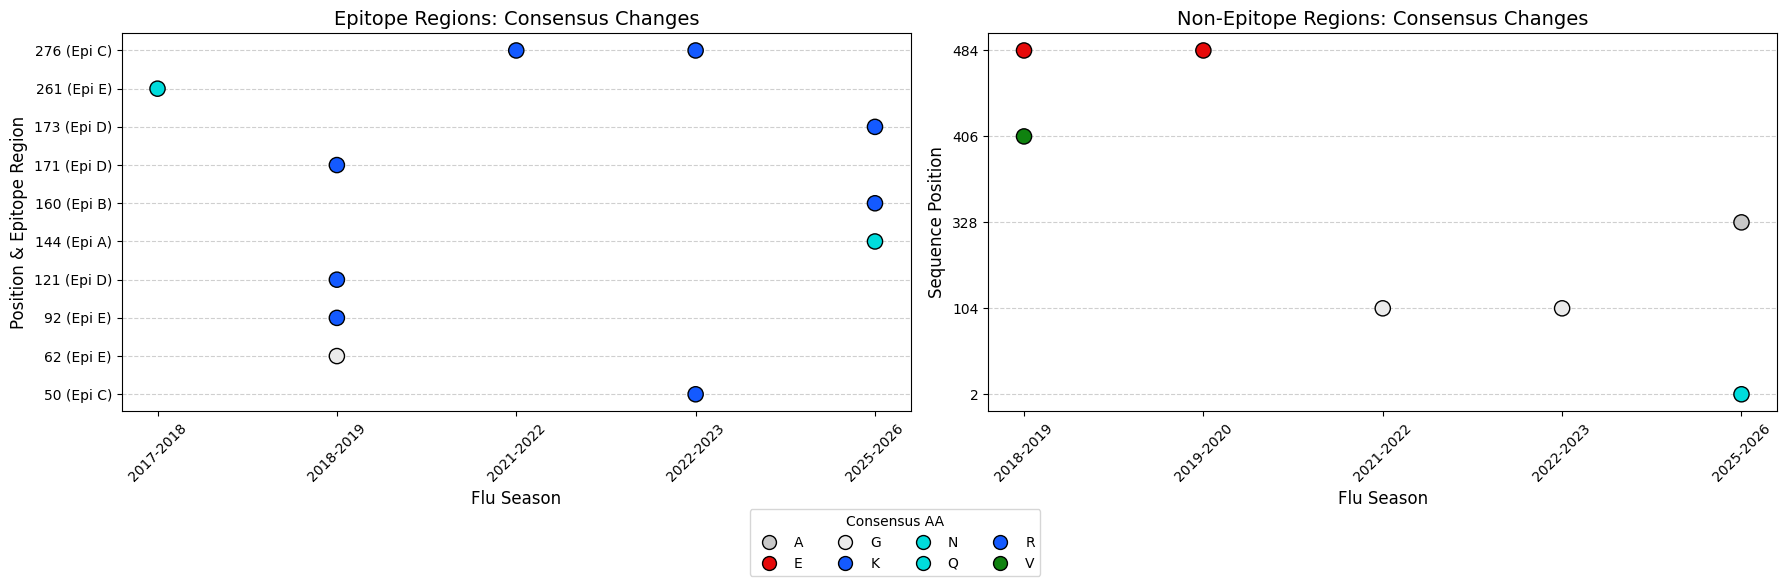

In [10]:
df_plot = changes_df[changes_df['Mutation_Type'] == 'Variant Emergence (>40%)'].copy()

if df_plot.empty:
    print("⚠️ No direct consensus changes found to plot.")
else:
    # Tag positions
    df_plot['Epitope_Site'] = df_plot['Position'].apply(lambda x: pos_to_epitope.get(x, 'Non-Epitope'))
    
    # Split DataFrames
    df_epi = df_plot[df_plot['Epitope_Site'] != 'Non-Epitope']
    df_non = df_plot[df_plot['Epitope_Site'] == 'Non-Epitope']
    
    # Determine exact ordered category Y-mappings
    unique_epi_pos = sorted(df_epi['Position'].unique())
    y_map_epi = {pos: i for i, pos in enumerate(unique_epi_pos)}
    y_labels_epi = [f"{p} (Epi {pos_to_epitope[p]})" for p in unique_epi_pos]
    
    unique_non_pos = sorted(df_non['Position'].unique())
    y_map_non = {pos: i for i, pos in enumerate(unique_non_pos)}
    y_labels_non = [str(p) for p in unique_non_pos]
    
    # Amino Acid Colors
    aa_colors = {
        'D': '#E60A0A', 'E': '#E60A0A', 'K': '#145AFF', 'R': '#145AFF',               
        'F': '#3232AA', 'Y': '#3232AA', 'W': '#B45AB4', 'N': '#00DCDC', 
        'Q': '#00DCDC', 'C': '#E6E600', 'M': '#E6E600', 'S': '#FA9600', 
        'T': '#FA9600', 'A': '#C8C8C8', 'G': '#EBEBEB', 'I': '#0F820F', 
        'L': '#0F820F', 'V': '#0F820F', 'P': '#DC9682', 'H': '#8282D2'                
    }
    
    # 3. Create the dual-plot figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, max(6, len(unique_epi_pos)*0.4)))
    
    # Graph A: Epitope Positions
    if not df_epi.empty:
        c_epi = df_epi['Plotted_AA'].map(aa_colors).fillna('#808080')
        y_coords_epi = df_epi['Position'].map(y_map_epi)
        
        ax1.scatter(df_epi['Season'], y_coords_epi, c=c_epi, s=120, edgecolors='black', zorder=3)
        ax1.set_yticks(range(len(unique_epi_pos)))
        ax1.set_yticklabels(y_labels_epi)
        ax1.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
        ax1.set_title('Epitope Regions: Consensus Changes', fontsize=14)
        ax1.set_xlabel('Flu Season', fontsize=12)
        ax1.set_ylabel('Position & Epitope Region', fontsize=12)
        ax1.tick_params(axis='x', rotation=45)
        
    # Graph B: Non-Epitope Positions
    if not df_non.empty:
        c_non = df_non['Plotted_AA'].map(aa_colors).fillna('#808080')
        y_coords_non = df_non['Position'].map(y_map_non)
        
        ax2.scatter(df_non['Season'], y_coords_non, c=c_non, s=120, edgecolors='black', zorder=3)
        ax2.set_yticks(range(len(unique_non_pos)))
        ax2.set_yticklabels(y_labels_non)
        ax2.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
        ax2.set_title('Non-Epitope Regions: Consensus Changes', fontsize=14)
        ax2.set_xlabel('Flu Season', fontsize=12)
        ax2.set_ylabel('Sequence Position', fontsize=12)
        ax2.tick_params(axis='x', rotation=45)
    
    # Unified Legend
    unique_aas = sorted(df_plot['Plotted_AA'].unique())
    legend_elements = [
        mlines.Line2D([0], [0], marker='o', color='w', 
                        markerfacecolor=aa_colors.get(aa, '#808080'), 
                        markeredgecolor='black', markersize=10, label=aa)
        for aa in unique_aas
    ]
    
    # Place legend nicely outside the plots
    num_cols = (len(legend_elements) + 1) // 2
    fig.legend(handles=legend_elements, title='Consensus AA', 
                bbox_to_anchor=(0.5, 0.02), loc='lower center',
                ncol = num_cols)
    
    plt.tight_layout(rect=[0, 0.12, 1, 1])
    plt.show() 

In [ ]:
# Cell 4
if not changes_df.empty:
    print("Preparing data for Consensus Change plots...")
    
    # 1. Define Epitopes
    epitope_sites = {
        'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
        'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
        'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
        'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
        'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
    }
    
    # Reverse map for easy lookup
    pos_to_epitope = {}
    for ep, positions in epitope_sites.items():
        for p in positions:
            pos_to_epitope[p] = ep

    # 2. Filter for ONLY Consensus Changes
    df_plot = changes_df[changes_df['Mutation_Type'] == 'Consensus Change'].copy()
    
    if df_plot.empty:
        print("⚠️ No direct consensus changes found to plot.")
    else:
        # Tag positions
        df_plot['Epitope_Site'] = df_plot['Position'].apply(lambda x: pos_to_epitope.get(x, 'Non-Epitope'))
        
        # Split DataFrames
        df_epi = df_plot[df_plot['Epitope_Site'] != 'Non-Epitope']
        df_non = df_plot[df_plot['Epitope_Site'] == 'Non-Epitope']
        
        # Determine exact ordered category Y-mappings
        unique_epi_pos = sorted(df_epi['Position'].unique())
        y_map_epi = {pos: i for i, pos in enumerate(unique_epi_pos)}
        y_labels_epi = [f"{p} (Epi {pos_to_epitope[p]})" for p in unique_epi_pos]
        
        unique_non_pos = sorted(df_non['Position'].unique())
        y_map_non = {pos: i for i, pos in enumerate(unique_non_pos)}
        y_labels_non = [str(p) for p in unique_non_pos]
        
        # Amino Acid Colors
        aa_colors = {
            'D': '#E60A0A', 'E': '#E60A0A', 'K': '#145AFF', 'R': '#145AFF',               
            'F': '#3232AA', 'Y': '#3232AA', 'W': '#B45AB4', 'N': '#00DCDC', 
            'Q': '#00DCDC', 'C': '#E6E600', 'M': '#E6E600', 'S': '#FA9600', 
            'T': '#FA9600', 'A': '#C8C8C8', 'G': '#EBEBEB', 'I': '#0F820F', 
            'L': '#0F820F', 'V': '#0F820F', 'P': '#DC9682', 'H': '#8282D2'                
        }
        
        # ==========================================
        # FIGURE 1: EPITOPE REGIONS
        # ==========================================
        if not df_epi.empty:
            # Dynamic height based on number of positions, fixed width
            plt.figure(figsize=(10, max(5, len(unique_epi_pos)*0.4)))
            
            c_epi = df_epi['Plotted_AA'].map(aa_colors).fillna('#808080')
            y_coords_epi = df_epi['Position'].map(y_map_epi)
            
            plt.scatter(df_epi['Season'], y_coords_epi, c=c_epi, s=120, edgecolors='black', zorder=3)
            plt.yticks(range(len(unique_epi_pos)), y_labels_epi)
            plt.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
            
            plt.title('Epitope Regions: Consensus Changes', fontsize=14, pad=15)
            plt.xlabel('Flu Season', fontsize=12)
            plt.ylabel('Position & Epitope Region', fontsize=12)
            plt.xticks(rotation=45, ha='right')
            
            # Legend specific to Figure 1
            unique_aas_epi = sorted(df_epi['Plotted_AA'].unique())
            legend_elements_epi = [
                mlines.Line2D([0], [0], marker='o', color='w', 
                              markerfacecolor=aa_colors.get(aa, '#808080'), 
                              markeredgecolor='black', markersize=10, label=aa)
                for aa in unique_aas_epi
            ]
            plt.legend(handles=legend_elements_epi, title='Consensus AA', 
                       bbox_to_anchor=(1.05, 1), loc='upper left')
            
            plt.tight_layout()
            plt.show() # Renders Figure 1

        print("\n" + "-"*40 + "\n") # Visual separator in the notebook output

        # ==========================================
        # FIGURE 2: NON-EPITOPE REGIONS
        # ==========================================
        if not df_non.empty:
            # Dynamic height based on number of positions, fixed width
            plt.figure(figsize=(10, max(5, len(unique_non_pos)*0.4)))
            
            c_non = df_non['Plotted_AA'].map(aa_colors).fillna('#808080')
            y_coords_non = df_non['Position'].map(y_map_non)
            
            plt.scatter(df_non['Season'], y_coords_non, c=c_non, s=120, edgecolors='black', zorder=3)
            plt.yticks(range(len(unique_non_pos)), y_labels_non)
            plt.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)
            
            plt.title('Non-Epitope Regions: Consensus Changes', fontsize=14, pad=15)
            plt.xlabel('Flu Season', fontsize=12)
            plt.ylabel('Sequence Position', fontsize=12)
            plt.xticks(rotation=45, ha='right')
            
            # Legend specific to Figure 2
            unique_aas_non = sorted(df_non['Plotted_AA'].unique())
            legend_elements_non = [
                mlines.Line2D([0], [0], marker='o', color='w', 
                              markerfacecolor=aa_colors.get(aa, '#808080'), 
                              markeredgecolor='black', markersize=10, label=aa)
                for aa in unique_aas_non
            ]
            plt.legend(handles=legend_elements_non, title='Consensus AA', 
                       bbox_to_anchor=(1.05, 1), loc='upper left')
            
            plt.tight_layout()
            plt.show() # Renders Figure 2

else:
    print("⚠️ No mutations were found between seasons.")